In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
import seaborn as sns
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/__notebook__.ipynb
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/__output__.json
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/__results__.html
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/bert_project_export.zip
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/custom.css
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/experiment_config.json
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/pca_coordinates.npy
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/pca_embeddings.npy
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/pca_sample_metadata.csv
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/test_predictions.csv
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/test_split.csv
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/train_split.csv
/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/training_history.csv
/kaggle/input

#  Phase 1: Analysis
Context: Only inputs and outputs were used for this phase, no deep-dive on model configurations or weights.

# Step 1: Loading the data
We load 2 files to start with:
- `test_predictions.csv`: the comments with the **human label** (`label`) and the **model output** (`toxicity_score`, `predicted_label`, `prediction_confidence`, `correct`).
- `train_split.csv`: what the model learned from.

In [2]:
test_predictions_df = pd.read_csv("/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/bert_project_export/test_predictions.csv")
test_predictions_df.head()
train_df = pd.read_csv("/kaggle/input/notebooks/vscharu/bert-toxicity-classifier/bert_project_export/train_split.csv")
# train_df.head()

# Step 2: Deriving additional columns
Then we add columns that make the comments interpretable and derive the additional indicators for future visualizations.
* `outcome` - TN / FP / FN / TP (comparison of `label` and `predicted_label`)
* `n_words` - comment length
* `identity_annotated` - raters were asked about identities for this comment (only about 23% of comments)
* `mentions_identity` - at least one identity column ≥ 0.5

In [3]:
ALL_IDENTITIES = ['asian', 'atheist', 'bisexual', 'black', 'buddhist', 'christian', 'female',
                  'heterosexual', 'hindu', 'homosexual_gay_or_lesbian',
                  'intellectual_or_learning_disability', 'jewish', 'latino', 'male', 'muslim',
                  'other_disability', 'other_gender', 'other_race_or_ethnicity', 'other_religion',
                  'other_sexual_orientation', 'physical_disability',
                  'psychiatric_or_mental_illness', 'transgender', 'white']


SUBTYPE_COLS = ['severe_toxicity', 'obscene', 'identity_attack', 'insult','threat', 'sexual_explicit'] 
                

def get_outcome(row):
    if row['label'] == 0 and row['predicted_label'] == 0:
        return 'TN'   # harmless, model said harmless
    if row['label'] == 0 and row['predicted_label'] == 1:
        return 'FP'   # harmless, model said toxic
    if row['label'] == 1 and row['predicted_label'] == 0:
        return 'FN'   # toxic, model said harmless
    return 'TP'       # toxic, model said toxic


def add_additonal_features(df):
    df = df.copy()
    comment = df['comment_text'].astype(str)
    df['n_words'] = comment.str.split().str.len()
    letters = comment.str.count(r'[A-Za-z]').clip(lower=1)
    df['identity_annotated'] = df['identity_annotator_count'] > 0
    # df['caps'] = comment.str.count(r'[A-Z]') / letters
    df['mentions_identity'] = (df[ALL_IDENTITIES].fillna(0) >= 0.5).any(axis=1)
    # df['rater_agreement'] = (df['target'] - 0.5).abs() * 2

    if 'predicted_label' in df.columns:
        df['outcome'] = df.apply(get_outcome, axis=1)
    
    return df


test_predictions_df = add_additonal_features(test_predictions_df)
train_df = add_additonal_features(train_df)

print(f'test: {len(test_predictions_df):,} comments | train: {len(train_df):,}')
print(f"comments with identity annotations in test: {test_predictions_df['identity_annotated'].sum():,} "
      f"({test_predictions_df['identity_annotated'].mean():.1%})")
display(test_predictions_df['outcome'].value_counts())

test: 18,149 comments | train: 65,475
comments with identity annotations in test: 4,245 (23.4%)


outcome
TP    8854
TN    8395
FP     538
FN     362
Name: count, dtype: int64

# Step 3: Test data review
### Features selection and Preparation 

Before concluding the model predictions, we need to know what it is tested on: how many toxic comments, how clear the human labels are, and how many comments mention each identity group.


- Plot 1: label counts (the snapshot is balanced on purpose, ~50/50; real platforms have far fewer toxic comments).
- Plot 2: target is the share of raters who said “toxic”. It shows how clear-cut the human labels are.
- Plot 3: how many annotated comments mention each group; the dotted line marks our minimum group size.

In [4]:
THRESHOLD = 0.5      
MIN_N = 30           # smallest group size we report (smaller groups are too noisy)


identity_annotated_samples = test_predictions_df[test_predictions_df['identity_annotated']] #around 23 percent
# print(identity_annotated_samples)

rows = []
for identity in ALL_IDENTITIES:
    # comments where at least half of the raters said this group is mentioned
    mentioning = identity_annotated_samples[identity_annotated_samples[identity] >= 0.5]

    rows.append({
        'identity': identity,
        'comments_mentioning': len(mentioning),
        'toxic_share': mentioning['label'].mean(),
    })

analysis = pd.DataFrame(rows)
# analysis.head()

### Visualization of the selected and newly created additional features
Comments:
Plot 1:

**Plot 2:**
There are no comments between 0.3 and 0.7. All comments are either clearly harmless (target below 0.3) or clearly toxic (0.7 or above). This is not a fully natural picture; the explanation can be that this data is just a snapshot with removed bordeline cases from the full Jigsaw data. Potential impact is that the model never saw ambiguous comments, neither in training nor in testing. The 95% accuracy is measured on clearly distinguished cases. On real platforms, with many borderline comments, it would likely do worse.

**Plot 3:**
For group sizes: the groups differ a lot in size. Big groups like female (533) and male (515) have several hundred comments, while small ones like other_disability have under 10. On a normal axis that runs to 1,000, a bar of 5 is practically not visible. It was decided to use a log scale, which makes 5, 50 and 500 equally readable.

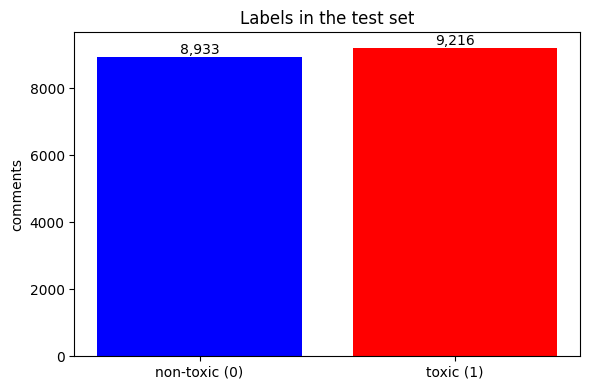

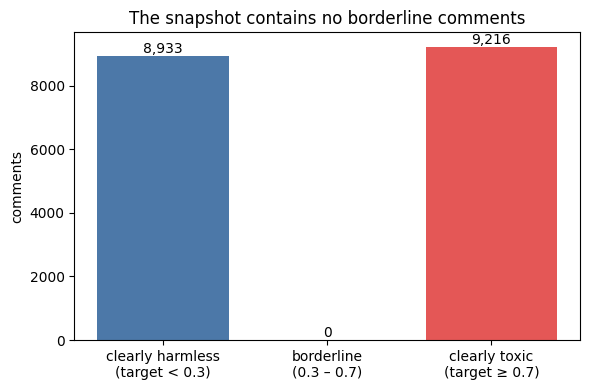

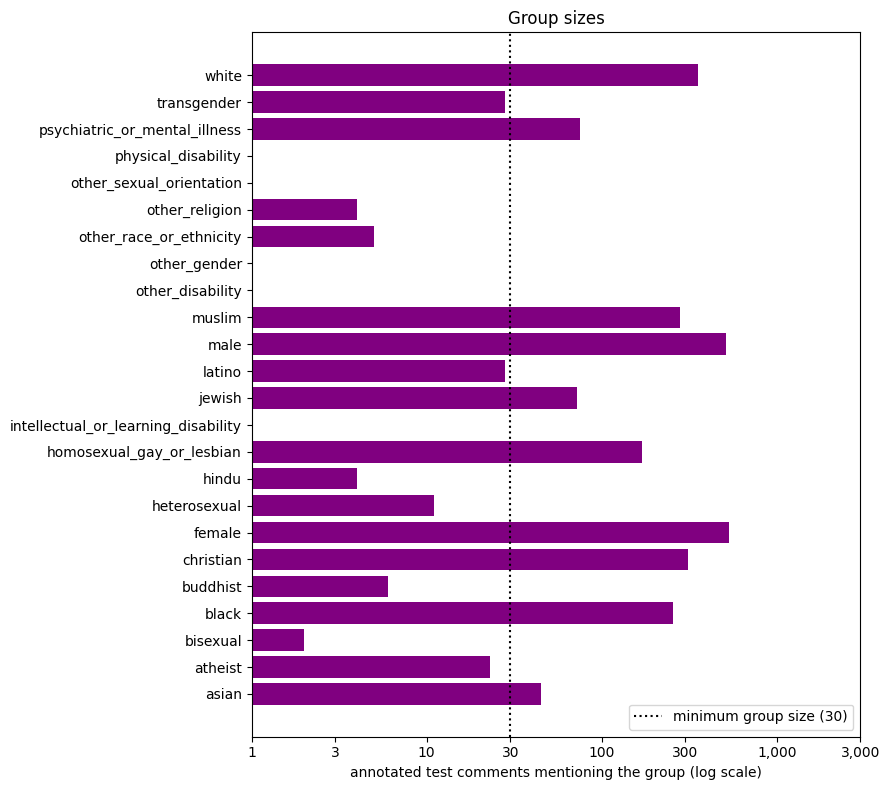

,identity,comments_mentioning,toxic_share
6,female,533,0.598
13,male,515,0.637
23,white,354,0.799
5,christian,310,0.429
14,muslim,281,0.758
3,black,256,0.855
9,homosexual_gay_or_lesbian,170,0.753
21,psychiatric_or_mental_illness,75,0.747
11,jewish,72,0.708
0,asian,45,0.533


In [5]:
# Plot 1: labels in the test set
counts = test_predictions_df['label'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(['non-toxic (0)', 'toxic (1)'], counts.values, color=['blue', 'red'])
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
ax.set_ylabel('comments')
ax.set_title('Labels in the test set')
plt.tight_layout()
plt.show()


# Plot 2: how clear are the human labels
fig, ax2 = plt.subplots(figsize=(6, 4))

# Right: the same data in three groups
clarity = pd.cut(test_predictions_df['target'],
                 bins=[0, 0.3, 0.7, 1.0001],
                 labels=['clearly harmless\n(target < 0.3)',
                         'borderline\n(0.3 – 0.7)',
                         'clearly toxic\n(target ≥ 0.7)'],
                 right=False)
clarity_counts = clarity.value_counts().reindex(clarity.cat.categories)

ax2.bar(clarity_counts.index, clarity_counts.values, color=['#4C78A8', 'lightgrey', '#E45756'])
for i, v in enumerate(clarity_counts.values):
    ax2.text(i, v, f'{v:,}', ha='center', va='bottom')
ax2.set_ylabel('comments')
ax2.set_title('The snapshot contains no borderline comments')

plt.tight_layout()
plt.show()


# Plot 3: group sizes
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(analysis['identity'], analysis['comments_mentioning'], color='purple')
ax.axvline(MIN_N, color='black', ls=':', label=f'minimum group size ({MIN_N})')
axis_ticks = [1, 3, 10, 30, 100, 300, 1000, 3000]
ax.set_xscale('log')
ax.set_xticks(axis_ticks)
ax.set_xticklabels([f'{t:,}' for t in axis_ticks])
ax.minorticks_off()
ax.set_xlabel('annotated test comments mentioning the group (log scale)')
ax.set_title('Group sizes')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


display(analysis.sort_values('comments_mentioning', ascending=False).round(3))

# Step 4: Accuracy and errors
The model produces 538 false positives, i.e. about 6.0% of the 8,933 truly harmless comments are flagged as toxic, and 362 false negatives, i.e. about 3.9% of the 9,216 truly toxic comments are missed. So the model makes more mistakes by over-flagging harmless comments than by missing toxic ones.

**Plot 1: Confusion matrix**
The confusion matrix shows how many comments fall into each of the four outcomes (true negatives, false positives, false negatives, true positives). It shows how many errors there are, but not how sure the model was when it made them.

**Plot 2: Score distribution per true class**
The second plot shows the model’s scores for truly harmless and truly toxic comments, and therefore where the mistakes come from. Green bars show comments that humans labeled as harmless, red bars show comments labeled as toxic. The dashed line marks the model’s decision point (0.5). A good model places the green bars close to 0 and the red bars close to 1, and we can see that this is true for most comments. However, we notice two kinds of errors:
* Errors close to the line (scores around 0.4–0.6): only 36 of the 538 false positives and 18 of the 362 false negatives are in this range. So only a small part of the errors happens where the model was unsure.
* Errors far from the line: 334 false positives (62%) have a score above 0.9, and 227 false negatives (63%) have a score below 0.1. So most errors are made with high confidence: the model is very sure and still wrong. These are the most interesting cases and require further investigation.

,value
accuracy,0.9504
precision,0.9427
recall,0.9607
f1,0.9516
roc_auc,0.9897


,comments
"TP: toxic, model said toxic (correct)",8854
"TN: harmless, model said harmless (correct)",8395
"FP: harmless, but model said toxic (wrong)",538
"FN: toxic, but model said harmless (wrong)",362


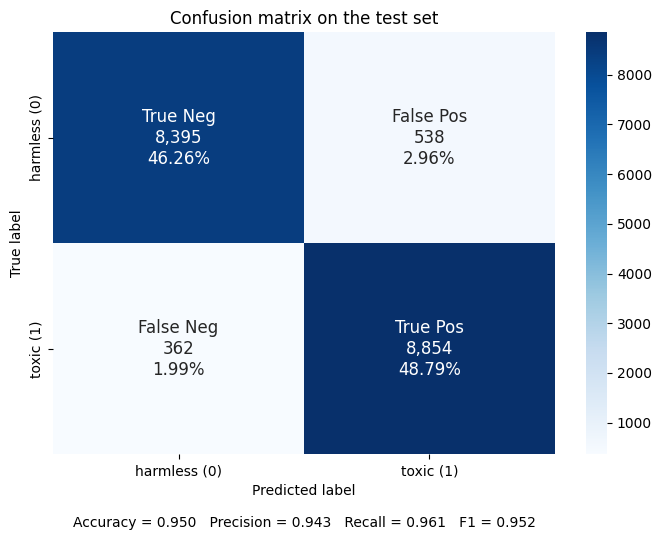

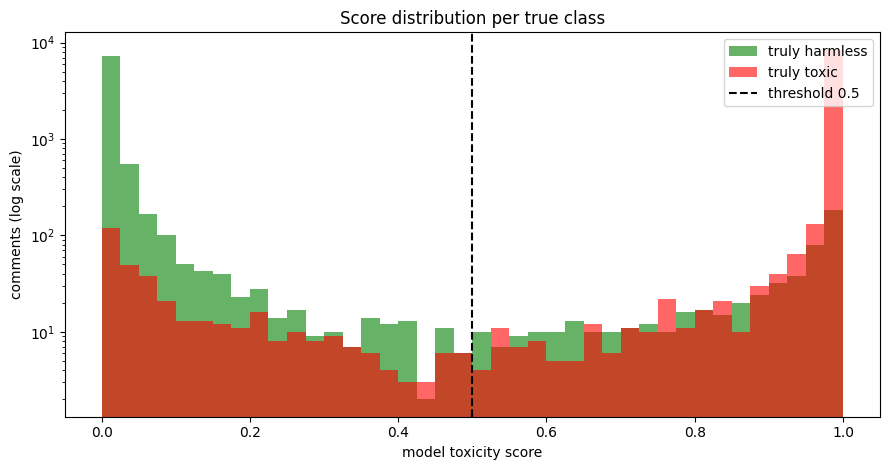

FP unsure (0.5-0.6): 36 | very sure (> 0.9): 334
FN unsure (0.4-0.5): 18 | very sure (< 0.1): 227


In [6]:
y = test_predictions_df['label']               # human answer (0/1)
y_predicted = test_predictions_df['predicted_label']  # model answer (0/1)
score = test_predictions_df['toxicity_score']  # model probability (0-1)

metrics = pd.Series({
    'accuracy': accuracy_score(y, y_predicted),
    'precision': precision_score(y, y_predicted),
    'recall': recall_score(y, y_predicted),
    'f1': f1_score(y, y_predicted),
    'roc_auc': roc_auc_score(y, score),
}, name='value')

tn, fp, fn, tp = confusion_matrix(y, y_predicted, labels=[0, 1]).ravel()
fpr = fp / (fp + tn)
fnr = fn / (fn + tp)

display(metrics.round(4).to_frame())

counts = pd.Series({
    'TP: toxic, model said toxic (correct)': tp,
    'TN: harmless, model said harmless (correct)': tn,
    'FP: harmless, but model said toxic (wrong)': fp,
    'FN: toxic, but model said harmless (wrong)': fn,
}, name='comments')
display(counts.to_frame())


# Plot 1: confusion matrix
cf_matrix = np.array([[tn, fp],
                      [fn, tp]])

group_names = ['True Neg', 'False Pos', 'False Neg', 'True Pos']
group_counts = [f'{value:,}' for value in cf_matrix.flatten()]
group_percentages = [f'{value:.2%}' for value in cf_matrix.flatten() / cf_matrix.sum()]

labels = [f'{name}\n{count}\n{percent}'
          for name, count, percent in zip(group_names, group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2, 2)

stats_text = (f"\n\nAccuracy = {metrics['accuracy']:.3f}   Precision = {metrics['precision']:.3f}   "
              f"Recall = {metrics['recall']:.3f}   F1 = {metrics['f1']:.3f}")

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cf_matrix, annot=labels, fmt='', cmap='Blues', ax=ax,
            xticklabels=['harmless (0)', 'toxic (1)'],
            yticklabels=['harmless (0)', 'toxic (1)'], annot_kws={'size': 12})
ax.set_ylabel('True label')
ax.set_xlabel('Predicted label' + stats_text)
ax.set_title('Confusion matrix on the test set')
plt.tight_layout()
plt.show()


# Plot 2: score distribution per true class
bins = np.linspace(0, 1, 41)

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(score[y == 0], bins=bins, alpha=0.6, color='green', label='truly harmless')
ax.hist(score[y == 1], bins=bins, alpha=0.6, color='red', label='truly toxic')
ax.axvline(THRESHOLD, color='black', ls='--', label='threshold 0.5')
ax.set_yscale('log')
ax.set_xlabel('model toxicity score')
ax.set_ylabel('comments (log scale)')
ax.set_title('Score distribution per true class')
ax.legend()
plt.tight_layout()
plt.show()

fp_scores = score[(y == 0) & (y_predicted == 1)]
fn_scores = score[(y == 1) & (y_predicted == 0)]
print('FP unsure (0.5-0.6):', ((fp_scores >= 0.5) & (fp_scores < 0.6)).sum(), '| very sure (> 0.9):', (fp_scores > 0.9).sum())
print('FN unsure (0.4-0.5):', ((fn_scores >= 0.4) & (fn_scores < 0.5)).sum(), '| very sure (< 0.1):', (fn_scores < 0.1).sum())

# Step 5: Confidence
The idea is to check whether we can trust the model’s scores. The scores are divided into 10 ranges (0–0.1, 0.1–0.2, …). For each range we plot one point with two coordinates: x is the model’s average score in that range (how toxic the model thinks these comments are), and y is the share of comments in that range that humans labeled as toxic (how toxic they really are). The dashed diagonal shows perfect calibration, and the orange line shows our model. This gives three scenarios:


1. On the diagonal: the score is reliable.
2. Below the diagonal: the model over-estimates toxicity; it considers comments more toxic than they really are.
3. Above the diagonal: the model under-estimates toxicity; it considers comments less toxic than they really are.

Looking at the plot below, we can see that near 0 and 1 the orange points are very close to the diagonal, so very confident scores are reliable. Around 0.35–0.4 the line only crosses the diagonal. In the range 0.1–0.3 the model under-estimates toxicity, and in the range 0.45–0.9 it clearly over-estimates it. This means that only scores close to 0 or 1 can be trusted; intermediate scores say little about how toxic a comment really is. The model is more confident when it is correct (average confidence 0.988) than when it is wrong (0.882), but even its mistakes are usually made with high confidence.

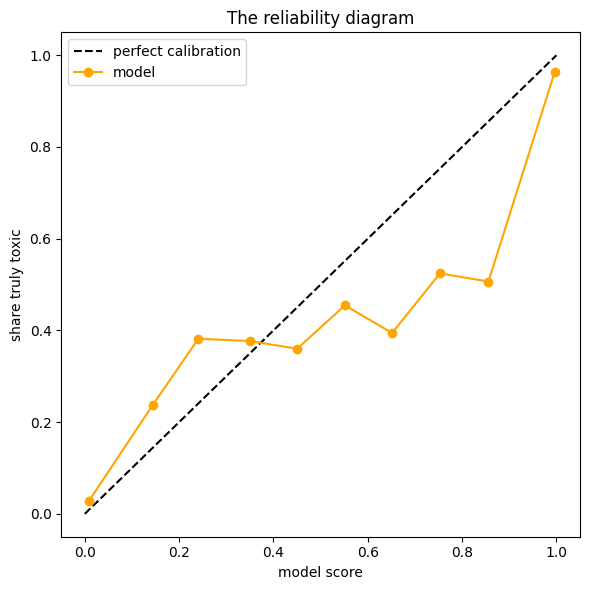

average confidence when correct: 0.988
average confidence when wrong:   0.882


In [7]:
share_toxic, mean_score = calibration_curve(y, score, n_bins=10)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], ls='--', color='black', label='perfect calibration')
ax.plot(mean_score, share_toxic, marker='o', color='orange', label='model')
ax.set_xlabel('model score')
ax.set_ylabel('share truly toxic')
ax.set_title('The reliability diagram')
ax.legend()
plt.tight_layout()
plt.show()

# Confidence of correct vs. wrong predictions
correct = test_predictions_df['correct'].astype(str).str.lower().isin(['true', '1'])
confidence = test_predictions_df['prediction_confidence']

print(f'average confidence when correct: {confidence[correct].mean():.3f}')
print(f'average confidence when wrong:   {confidence[~correct].mean():.3f}')

In [8]:
cols = ['outcome', 'toxicity_score', 'target', 'comment_text']
print('Most confident FP (harmless by human label, model very sure it is toxic):')
display(test_predictions_df[test_predictions_df['outcome'] == 'FP'].nlargest(5, 'toxicity_score')[cols])
print('\nMost confident FN (toxic by human label, model very sure it is harmless):')
display(test_predictions_df[test_predictions_df['outcome'] == 'FN'].nsmallest(5, 'toxicity_score')[cols])

Most confident FP (harmless by human label, model very sure it is toxic):


,outcome,toxicity_score,target,comment_text
17396,FP,0.999658,0.225806,Anyone who tells you otherwise is a lying lefty
11066,FP,0.999564,0.000000,Just heard the CIRCUS Barnum and Bailey is cl...
10228,FP,0.999426,0.287879,Ohh... you like to wear women's underwear do ...
13334,FP,0.999321,0.000000,"""It is better to remain silent and be thought ..."
11375,FP,0.999319,0.000000,The work farce Do you or nearly all Canadians ...



Most confident FN (toxic by human label, model very sure it is harmless):


,outcome,toxicity_score,target,comment_text
8719,FN,0.000379,1.000000,"Shame on you for ""politicizing"" an important m..."
7902,FN,0.000400,0.833333,About the same percentage as Trumplodites in A...
3757,FN,0.000443,0.800000,No doubt it was Republican input that ruined t...
1805,FN,0.000469,0.800000,The only thing that women have been able to do...
8441,FN,0.000578,1.000000,Instead of trying to unite the country our pri...


# Step 6: Features deep-dive
The subtype columns review (insult, identity_attack, …) - human ratings of the kind of toxicity.

**Intermediate step**
* TN vs. FP (both truly harmless): the values are low in both rows, as expected for harmless comments. But the false positives consistently have a bit more of every toxicity type: a few raters saw something insulting or identity-related in them, just not enough to make the majority say “toxic”. The length is about the same, so length doesn’t explain these errors.
* FN vs. TP (both truly toxic): missed toxic comments contain more threats and identity attacks. These are forms of toxicity that can be phrased in a seemingly polite way, e.g. threatening or hateful statements without crude words. Additionally, missed toxic comments contain fewer swear words. The model relies on obscene language, and toxicity without it is harder to catch. Besides that, they’re about twice as long (73 vs. 35 words). Two possible reasons: the toxic part is expanded by much harmless text around it, and the model only reads the first 128 tokens, so in long comments the toxic part may simply be cut. This is supported by the share of long comments: 34.0% of the missed toxic comments have more than 100 words, compared with only 5.2% of the correctly detected ones.

In [9]:
# df = test_predictions_df

# table = df.groupby('outcome')[SUBTYPE_COLS + ['n_words']].mean()
# table = table.rename(index={
#     'TN': 'TN: harmless, model said harmless (correct)',
#     'FP': 'FP: harmless, but model said toxic (wrong)',
#     'FN': 'FN: toxic, but model said harmless (wrong)',
#     'TP': 'TP: toxic, model said toxic (correct)',
# })
# display(table.round(3))

# for outcome in ['FN', 'TP']:
#     part = df[df['outcome'] == outcome]
#     long_share = (part['n_words'] > 100).mean()
#     print(f'{outcome}: {long_share:.1%} of comments have more than 100 words')


Earlier we noticed that the toxic comments the model missed were about twice as long as the ones it caught. So we looked at this more closely: we sorted the toxic comments by length and checked how many the model missed in each group. The pattern is clear. Up to 100 words, the model misses only 2–4% of toxic comments, but above 100 words it misses 21.1% (123 of 582). Long comments are only 6% of all toxic comments, yet they account for about a third of all the toxic comments the model missed (123 of 362). 

The interesting point is that the jump occurs exactly at the model’s reading limit. The model only processes the first 128 tokens (word pieces), which is roughly 90–100 words, and the rest of a longer comment is cut. If the toxic part comes later in the comment, the model never sees it. We don’t know exactly where in each comment the toxic part is.

1-25 words: 125 of 4679 toxic comments missed (2.7%)
26-50 words: 51 of 2437 toxic comments missed (2.1%)
51-100 words: 63 of 1518 toxic comments missed (4.2%)
over 100 words: 123 of 582 toxic comments missed (21.1%)


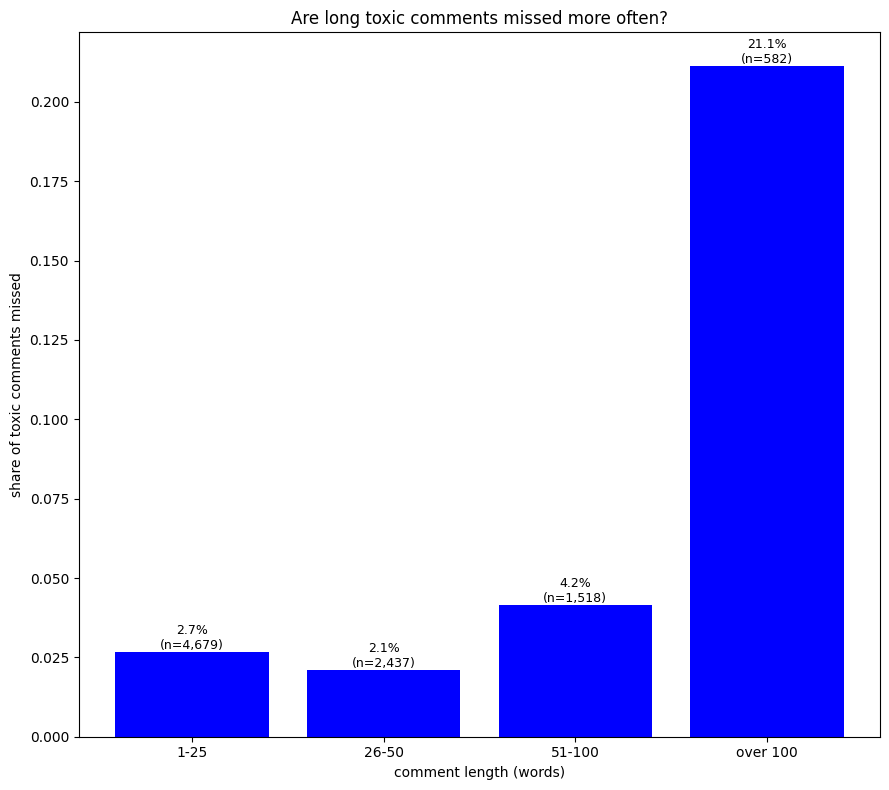

In [10]:
toxic = test_predictions_df[test_predictions_df['label'] == 1]

length_groups = [('1-25', 1, 25), ('26-50', 26, 50), ('51-100', 51, 100), ('over 100', 101, 100000)]

names = []
miss_rates = []
counts = []

for name, shortest, longest in length_groups:
    group = toxic[(toxic['n_words'] >= shortest) & (toxic['n_words'] <= longest)]
    missed = (group['predicted_label'] == 0).sum()
    names.append(name)
    counts.append(len(group))
    miss_rates.append(missed / len(group))
    print(f'{name} words: {missed} of {len(group)} toxic comments missed ({missed / len(group):.1%})')

fig, ax = plt.subplots(figsize=(9, 8))
ax.bar(names, miss_rates, color='blue')
for i in range(len(names)):
    ax.text(i, miss_rates[i], f'{miss_rates[i]:.1%}\n(n={counts[i]:,})', ha='center', va='bottom', fontsize=9)
ax.set_xlabel('comment length (words)')
ax.set_ylabel('share of toxic comments missed')
ax.set_title('Are long toxic comments missed more often?')
plt.tight_layout()
plt.show()

# Step 7: Human VS Model Comparison (incl. Identity Mentions Check)
The main question is whether the model treats comments about identity groups unfairly. We compare annotated comments that mention an identity group with annotated comments that don’t. Both were checked by raters in the same way, so the main difference between them is the identity mention. This table is the first, simple test: before looking at individual groups (Muslim, Black, women…), we check whether mentioning any identity at all changes how often the model makes mistakes. If the model behaves differently on them, the identity mention is the likely reason. Besides that, the rates we calculated are key indicators:


1. FP: if harmless comments that mention an identity get flagged more often than harmless comments without one, that’s the first sign of identity bias: the model reacts to the identity word, not to actual toxicity.
2. FN: it checks whether toxic comments about identity groups are missed more often, which would mean attacks against those groups could slip through.

Looking at the obtained results, we see that harmless comments that mention an identity group were flagged as toxic in 15.0% of cases (96 of 638), compared with 6.3% (74 of 1,178) for harmless comments without an identity mention. That’s more than twice as often. When it comes to false negatives, the situation is similar but less pronounced: toxic comments about identity groups were also missed more often (5.4% vs. 3.8%), but the difference is smaller.

Potential root cause: the model treats harmless comments as toxic more often when an identity is mentioned. A possible explanation is visible in the data itself: about 67% of the comments that mention an identity group are toxic (1,273 of 1,911), compared with about 50% of comments without one. If the training data shows the same pattern, the model may have learned the dependency.

In [11]:
df = test_predictions_df

# split the comments into three groups
checked = df[df['identity_annotated']]
with_identity = checked[checked['mentions_identity']]
without_identity = checked[~checked['mentions_identity']]
not_checked = df[~df['identity_annotated']]


def error_rates(data):
    harmless = data[data['label'] == 0]
    toxic = data[data['label'] == 1]
    false_positive_rate = (harmless['predicted_label'] == 1).mean()   # harmless but flagged
    false_negative_rate = (toxic['predicted_label'] == 0).mean()      # toxic but missed
    return false_positive_rate, false_negative_rate


fpr_with, fnr_with = error_rates(with_identity)
fpr_without, fnr_without = error_rates(without_identity)
fpr_not, fnr_not = error_rates(not_checked)

error_by_group = pd.DataFrame({
    'group': ['checked and mentions an identity group', 'checked, no identity mentioned', 'not checked for identity'],
    'comments': [len(with_identity), len(without_identity), len(not_checked)],
    'false positive rate': [fpr_with, fpr_without, fpr_not],
    'false negative rate': [fnr_with, fnr_without, fnr_not],
})
display(error_by_group.round(3))

for name, data in [('with identity', with_identity), ('without identity', without_identity)]:
    harmless = data[data['label'] == 0]
    flagged = (harmless['predicted_label'] == 1).sum()
    print(f'{name}: {flagged} of {len(harmless)} harmless comments flagged')

for name, data in [('with identity', with_identity), ('without identity', without_identity)]:
    toxic_count = (data['label'] == 1).sum()
    print(f'{name}: {toxic_count} of {len(data)} comments are toxic ({toxic_count / len(data):.1%})')

,group,comments,false positive rate,false negative rate
0,checked and mentions an identity group,1911,0.150,0.054
1,"checked, no identity mentioned",2334,0.063,0.038
2,not checked for identity,13904,0.052,0.037


with identity: 96 of 638 harmless comments flagged
without identity: 74 of 1178 harmless comments flagged
with identity: 1273 of 1911 comments are toxic (66.6%)
without identity: 1156 of 2334 comments are toxic (49.5%)


We split the errors into sub-groups to see which kind of comments the model gets wrong: was the human label agreed, and does the comment mention an identity? What the tables show:

* False positives: “no rater said toxic” (target = 0) vs. “some raters said toxic” (target > 0), split by identity mention.
* False negatives: “strong majority” (≥ 80% said toxic) vs. “weaker majority” (70–80%), split by identity mention.

These thresholds are used because the dataset contains no comments between 0.3 and 0.7. Looking at obtained results:

**False positives (538 in total):**
259 (48%) were judged harmless by every rater, so the model is clearly wrong on almost half of its false positives. Unclear labels can’t explain those.
96 false positives mention an identity group, about 18%. That share is the same in both rows, so identity-related errors are not concentrated among the “some raters said toxic” comments.


**False negatives (362 in total):**
344 (95%) are comments that at least 80% of the raters found toxic. The model misses comments almost everyone agreed were toxic, not borderline ones. Combined with our earlier finding (long comments, fewer swear words), these are probably long or “polite” toxic comments.
69 (19%) mention an identity, similar to the false positives.

The examples: they’re about crime, terrorism and politics (Paul Bernardo, a serial killer; Nidal Hasan, “Islamic terrorist”; “public scandal”; “black vote”). So these aren’t neutral descriptions like “my Muslim neighbor”. They’re harmless comments discussing controversial topics. The model seems to react to sensitive topics and words, even when the comment itself is factual.

In [12]:
df = test_predictions_df
fp = df[df['outcome'] == 'FP']   # harmless but flagged
fn = df[df['outcome'] == 'FN']   # toxic but missed


print('Examples: no rater said toxic, mentions an identity, but flagged by model')
display(fp[(fp['target'] == 0) & fp['mentions_identity']][['toxicity_score', 'comment_text', 'target']].head(5))

print(f"FP judged harmless by every rater: {(fp['target'] == 0).sum()} of {len(fp)} ({(fp['target'] == 0).mean():.1%})")
print(f"FP that mention an identity: {fp['mentions_identity'].sum()} of {len(fp)} ({fp['mentions_identity'].mean():.1%})")
print(f"FN with a strong majority (>= 0.8): {(fn['target'] >= 0.8).sum()} of {len(fn)} ({(fn['target'] >= 0.8).mean():.1%})")
print(f"FN that mention an identity: {fn['mentions_identity'].sum()} of {len(fn)} ({fn['mentions_identity'].mean():.1%})")

Examples: no rater said toxic, mentions an identity, but flagged by model


,toxicity_score,comment_text,target
9271,0.898919,There was something wrong with Paul Bernardo a...,0.0
9460,0.958191,How so? When Nidal Hasan- an Islamic Terroris...,0.0
9583,0.974309,"Take a look at those words ""public scandal."" W...",0.0
9613,0.741721,If you don't have any evidence that black vote...,0.0
9699,0.959696,Due process is a fundamental principal for jus...,0.0


FP judged harmless by every rater: 259 of 538 (48.1%)
FP that mention an identity: 96 of 538 (17.8%)
FN with a strong majority (>= 0.8): 344 of 362 (95.0%)
FN that mention an identity: 69 of 362 (19.1%)


The previous table showed that harmless comments mentioning an identity are flagged more than twice as often (15.0% vs. 6.3%). Here we check which groups cause this. For each identity group with at least 30 harmless comments, we compute the share that the model wrongly flagged as toxic. 

Checking the results:
* The over-flagging is concentrated in four groups.
* Harmless comments mentioning Black people (43.2%, 16 of 37), White people (36.6%, 26 of 71), gay or lesbian people (31.0%, 13 of 42) and Muslims (26.5%, 18 of 68) are wrongly flagged 4–7 times as often as the baseline. 
* Comments mentioning Christians, women or men are only slightly above it (9.6–11.3%). Since both Black and White are strongly affected, the model seems to react to the topic of race in general, not to one specific group.

The big limitation we need to consider is that only 7 of the 24 identity groups had enough harmless comments (meeting our min threshold of at least 30). Some groups are small (e.g. 37 comments for Black), so their exact rates are uncertain, but the difference from the baseline is large enough in all four cases.

In [13]:
MIN_N = 30   # only show groups with at least 30 harmless comments

checked = test_predictions_df[test_predictions_df['identity_annotated']]
harmless = checked[checked['label'] == 0]

# baseline: harmless comments without any identity mention
no_identity = harmless[~harmless['mentions_identity']]
baseline_fpr = (no_identity['predicted_label'] == 1).mean()

rows = []
for identity in ALL_IDENTITIES:
    group = harmless[harmless[identity] >= 0.5]
    if len(group) >= MIN_N:
        rows.append({
            'group': identity,
            'harmless comments': len(group),
            'flagged': (group['predicted_label'] == 1).sum(),
            'false positive rate': (group['predicted_label'] == 1).mean(),
        })

group_fpr = pd.DataFrame(rows).sort_values('false positive rate')
display(group_fpr.round(3))


,group,harmless comments,flagged,false positive rate
4,male,187,18,0.096
2,female,214,24,0.112
1,christian,177,20,0.113
5,muslim,68,18,0.265
3,homosexual_gay_or_lesbian,42,13,0.310
6,white,71,26,0.366
0,black,37,16,0.432


# Step 8: Training data review
In the previous step we found that harmless comments mentioning certain identity groups are wrongly flagged much more often than others. The next question is why. A model learns only from its training data, so a natural hypothesis is: if comments mentioning a group were mostly toxic in the training data, the model may have learned to associate the group’s name itself with toxicity.

To test this, we compared two numbers for each identity group:
* left chart: how often comments mentioning the group were toxic in the training data, i.e. what the model saw while learning;
* right chart: how often harmless comments mentioning the group are wrongly flagged in the test data, i.e. how the model behaves now.

The dashed lines are the baselines: comments that mention no identity group (50.4% toxic in training, 6.3% wrongly flagged in test). The training baseline is about 50% because the dataset was built to be balanced between toxic and harmless comments, so groups should be compared with this line rather than with real-world numbers.

Looking at the plots:
The groups that are over-flagged most (Black, White, gay/lesbian, Muslim; 26–43% false positives vs. 6.3% baseline) are exactly the groups whose training comments were mostly toxic (73–84% vs. 50.4% baseline). This suggests that the model learned a shortcut: because these identity words appeared mainly in toxic comments during training, the model treats the word itself as a sign of toxicity, even in harmless comments.

Note: gender terms are an exception; comments mentioning men or women were also more often toxic in training (59–62%), but they are only slightly over-flagged (10–11%). A possible reason is that gender is mentioned in many everyday, harmless contexts as well. Comments mentioning Christians were less often toxic in training (37%) but are still slightly over-flagged (11%).

,group,training comments,toxic share in training,false positive rate
0,male,1790,0.624,0.096
1,female,2020,0.589,0.112
2,christian,1084,0.369,0.113
3,muslim,1000,0.729,0.265
4,homosexual_gay_or_lesbian,539,0.800,0.310
5,white,1262,0.798,0.366
6,black,860,0.835,0.432


Baseline toxic share in training (no identity mentioned): 50.4%


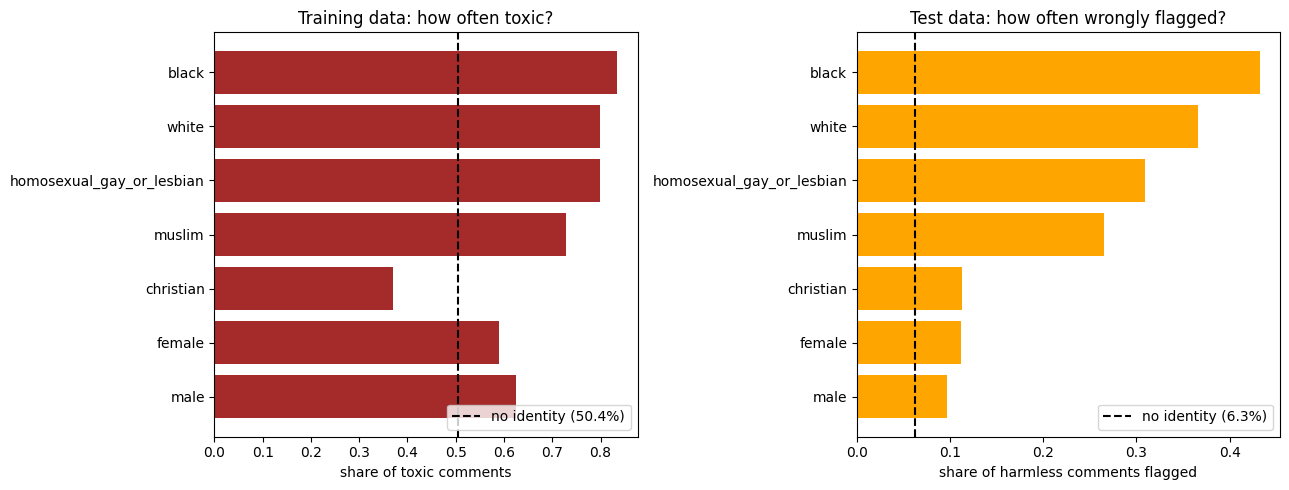

In [14]:
train_checked = train_df[train_df['identity_annotated']]

no_identity_train = train_checked[~train_checked['mentions_identity']]
baseline_train = no_identity_train['label'].mean()

rows = []
for identity in group_fpr['group']: # the same 7 groups as in the false positive chart
    mentions = train_checked[train_checked[identity] >= 0.5]
    rows.append({
        'group': identity,
        'training comments': len(mentions),
        'toxic share in training': mentions['label'].mean(),
    })

train_table = pd.DataFrame(rows).merge(group_fpr[['group', 'false positive rate']], on='group')
display(train_table.round(3))
print(f'Baseline toxic share in training (no identity mentioned): {baseline_train:.1%}')
data = train_table.sort_values('false positive rate')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
# left: how toxic were the group's comments in the training data?
ax1.barh(data['group'], data['toxic share in training'], color='brown')
ax1.axvline(baseline_train, color='black', ls='--', label=f'no identity ({baseline_train:.1%})')
ax1.set_xlabel('share of toxic comments')
ax1.set_title('Training data: how often toxic?')
ax1.legend(loc='lower right')

# right: how often are the group's harmless comments wrongly flagged?
ax2.tick_params(axis='y', labelleft=True)
ax2.barh(data['group'], data['false positive rate'], color='orange')
ax2.axvline(baseline_fpr, color='black', ls='--', label=f'no identity ({baseline_fpr:.1%})')
ax2.set_xlabel('share of harmless comments flagged')
ax2.set_title('Test data: how often wrongly flagged?')
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()